#Import Libraries

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

#Load the Dataset

In [4]:
df=pd.read_csv("/content/synthetic_medical_triage.csv")

In [5]:
df

,age,heart_rate,systolic_blood_pressure,oxygen_saturation,body_temperature,pain_level,chronic_disease_count,previous_er_visits,arrival_mode,triage_level
0,17.9,95.4,147.1,97.4,36.48,1,0,0,walk_in,0
1,79.2,147.9,158.6,96.0,39.35,10,4,2,ambulance,3
2,51.1,87.1,128.2,98.5,37.74,5,2,2,walk_in,1
3,56.8,84.7,147.2,92.5,37.55,4,4,4,walk_in,1
4,39.2,58.0,107.8,99.0,36.26,2,1,1,walk_in,0
...,...,...,...,...,...,...,...,...,...,...
17995,52.8,100.1,145.0,95.4,37.82,4,2,1,walk_in,1
17996,37.1,84.8,128.0,98.0,37.04,3,3,3,ambulance,1
17997,59.2,64.9,103.1,93.9,36.55,5,1,0,walk_in,1
17998,70.4,90.6,144.1,96.1,38.08,3,4,3,ambulance,0


#Explore the dataset

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18000 entries, 0 to 17999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      18000 non-null  float64
 1   heart_rate               18000 non-null  float64
 2   systolic_blood_pressure  18000 non-null  float64
 3   oxygen_saturation        18000 non-null  float64
 4   body_temperature         18000 non-null  float64
 5   pain_level               18000 non-null  int64  
 6   chronic_disease_count    18000 non-null  int64  
 7   previous_er_visits       18000 non-null  int64  
 8   arrival_mode             18000 non-null  object 
 9   triage_level             18000 non-null  int64  
dtypes: float64(5), int64(4), object(1)
memory usage: 1.4+ MB


In [7]:
df.shape

(18000, 10)

In [8]:
df.describe()

,age,heart_rate,systolic_blood_pressure,oxygen_saturation,body_temperature,pain_level,chronic_disease_count,previous_er_visits,triage_level
count,18000.000000,18000.000000,18000.000000,18000.000000,18000.000000,18000.000000,18000.000000,18000.000000,18000.000000
mean,44.716244,83.292322,128.072739,96.085183,37.224236,3.402111,1.072611,1.265056,0.697722
std,19.101056,16.964405,18.813277,3.330830,0.914978,2.039249,1.312204,1.454887,0.898923
min,0.000000,33.400000,65.800000,79.500000,34.470000,1.000000,0.000000,0.000000,0.000000
25%,31.200000,71.500000,114.900000,94.300000,36.580000,2.000000,0.000000,0.000000,0.000000
50%,44.000000,81.600000,126.900000,96.600000,37.120000,3.000000,1.000000,1.000000,0.000000
75%,57.500000,93.200000,139.900000,98.700000,37.770000,5.000000,2.000000,2.000000,1.000000
max,95.000000,152.300000,219.700000,100.000000,41.130000,10.000000,10.000000,11.000000,3.000000


#Check missing values

In [9]:
df.isnull().sum()

,0
age,0
heart_rate,0
systolic_blood_pressure,0
oxygen_saturation,0
body_temperature,0
pain_level,0
chronic_disease_count,0
previous_er_visits,0
arrival_mode,0
triage_level,0


In [10]:

df['heart_rate'] = df['heart_rate'].clip(lower=40, upper=200)

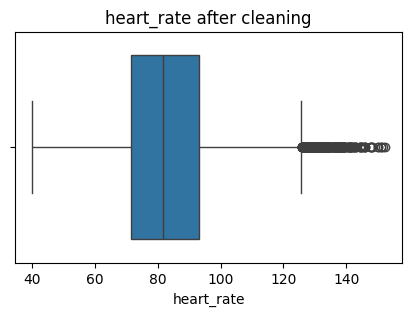

In [11]:
plt.figure(figsize=(5,3))
sns.boxplot(x=df['heart_rate'])
plt.title('heart_rate after cleaning')
plt.show()

In [12]:

df.duplicated().sum()

np.int64(0)

#Encoding

In [13]:
encoder=LabelEncoder()
df["arrival_mode"]=encoder.fit_transform(df["arrival_mode"])

In [14]:

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18000 entries, 0 to 17999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      18000 non-null  float64
 1   heart_rate               18000 non-null  float64
 2   systolic_blood_pressure  18000 non-null  float64
 3   oxygen_saturation        18000 non-null  float64
 4   body_temperature         18000 non-null  float64
 5   pain_level               18000 non-null  int64  
 6   chronic_disease_count    18000 non-null  int64  
 7   previous_er_visits       18000 non-null  int64  
 8   arrival_mode             18000 non-null  int64  
 9   triage_level             18000 non-null  int64  
dtypes: float64(5), int64(5)
memory usage: 1.4 MB


#Correlation Analysis

In [15]:
correlation=df.corr()

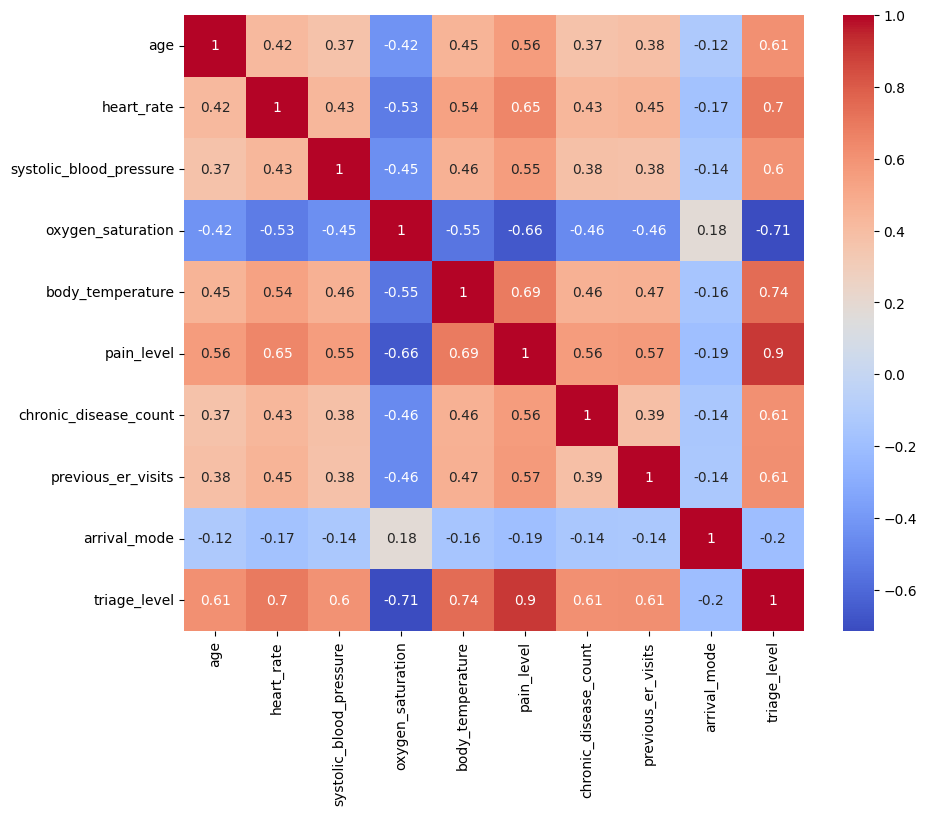

In [16]:
plt.figure(figsize=(10,8))
sns.heatmap(correlation, annot=True, cmap="coolwarm")
plt.show()

<Axes: xlabel='triage_level', ylabel='count'>

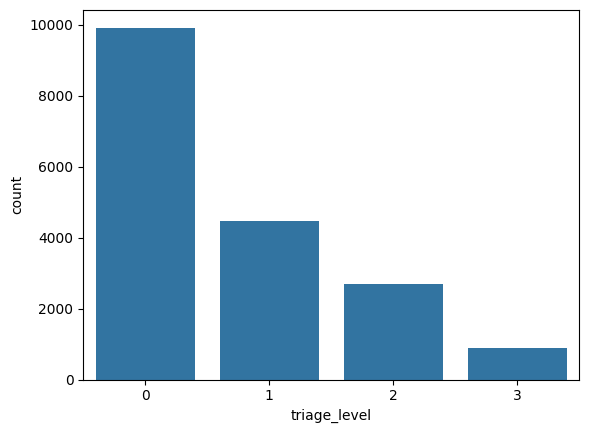

In [17]:
sns.countplot(x=df["triage_level"])

In [18]:
numeric_columns=df.select_dtypes(include=np.number).columns

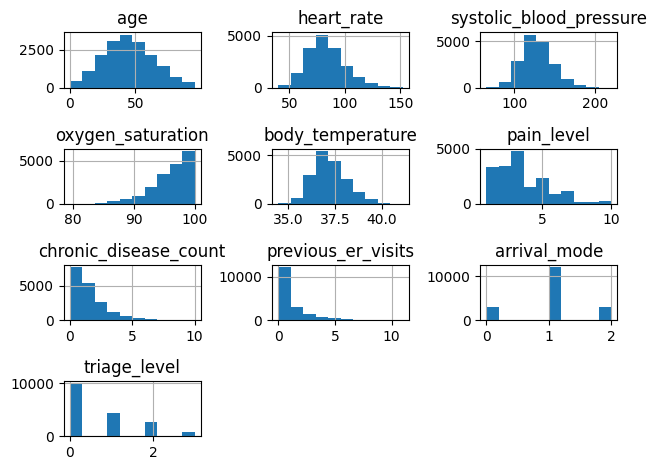

In [19]:
df[numeric_columns].hist()
plt.tight_layout()

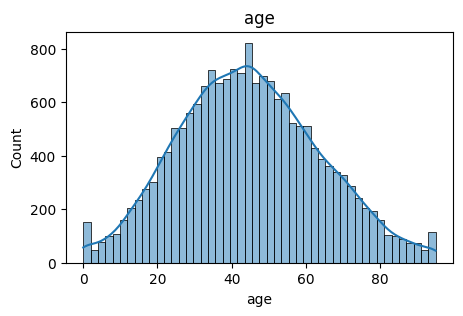

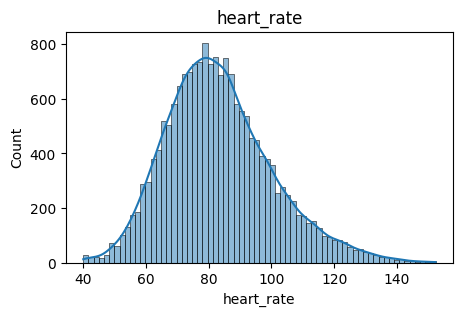

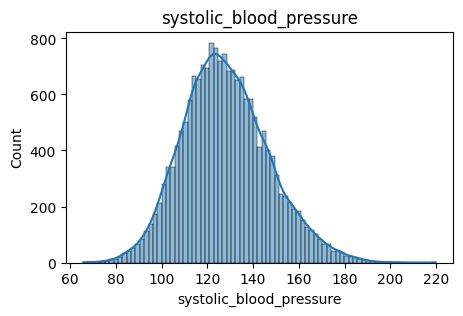

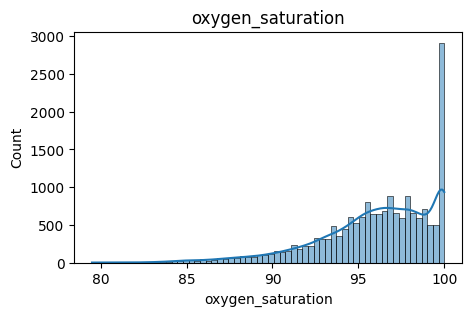

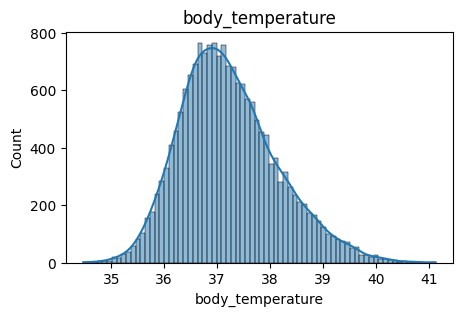

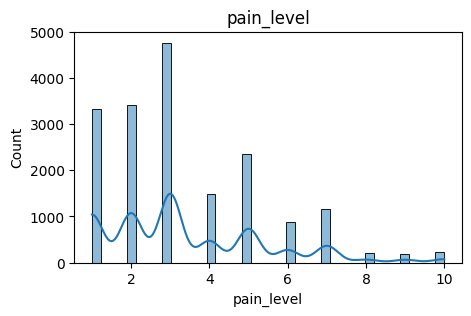

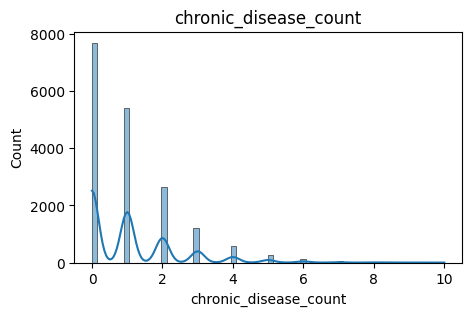

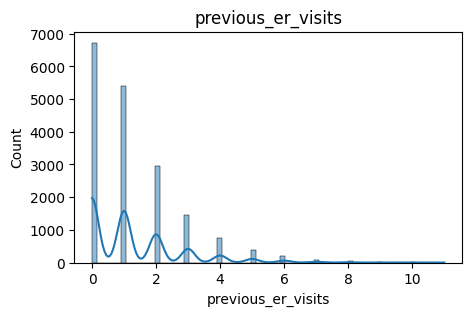

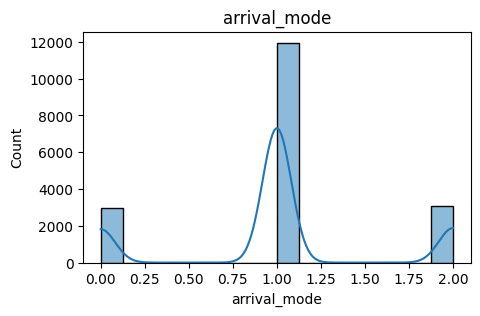

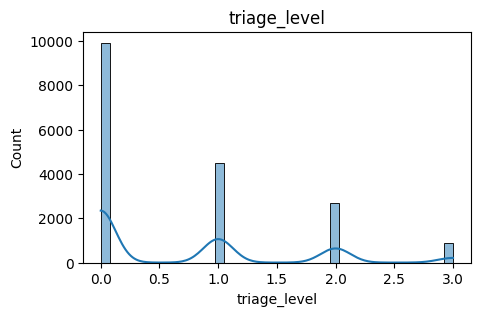

In [20]:

for col in df.columns:

    plt.figure(figsize=(5,3))

    sns.histplot(df[col], kde=True)

    plt.title(col)

    plt.show()


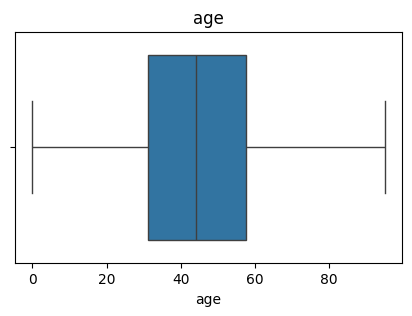

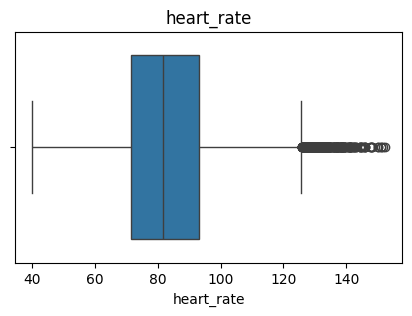

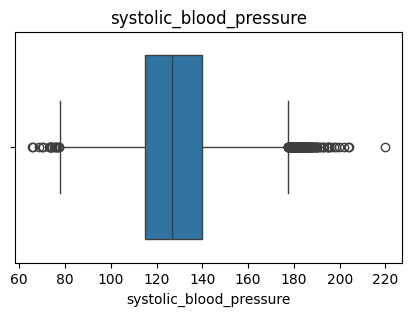

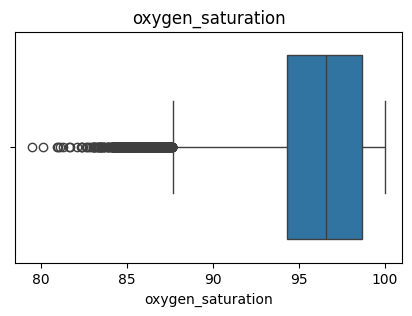

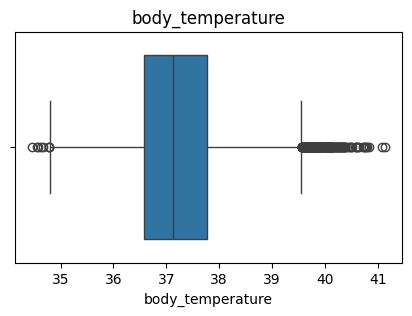

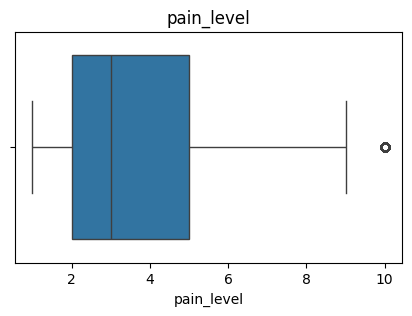

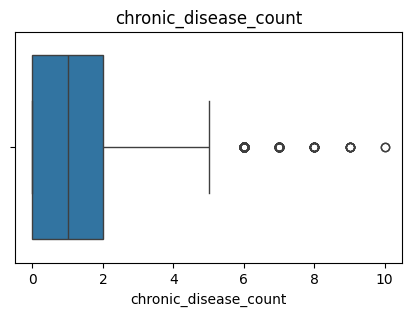

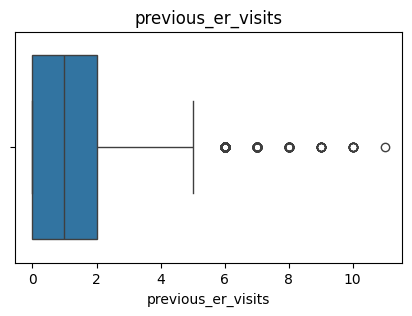

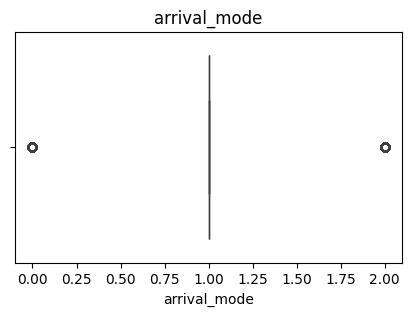

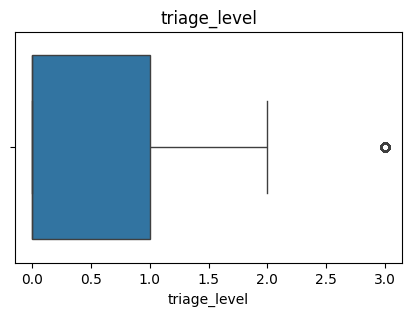

In [21]:
for col in numeric_columns:

    plt.figure(figsize=(5,3))

    sns.boxplot(x=df[col])

    plt.title(col)

    plt.show()

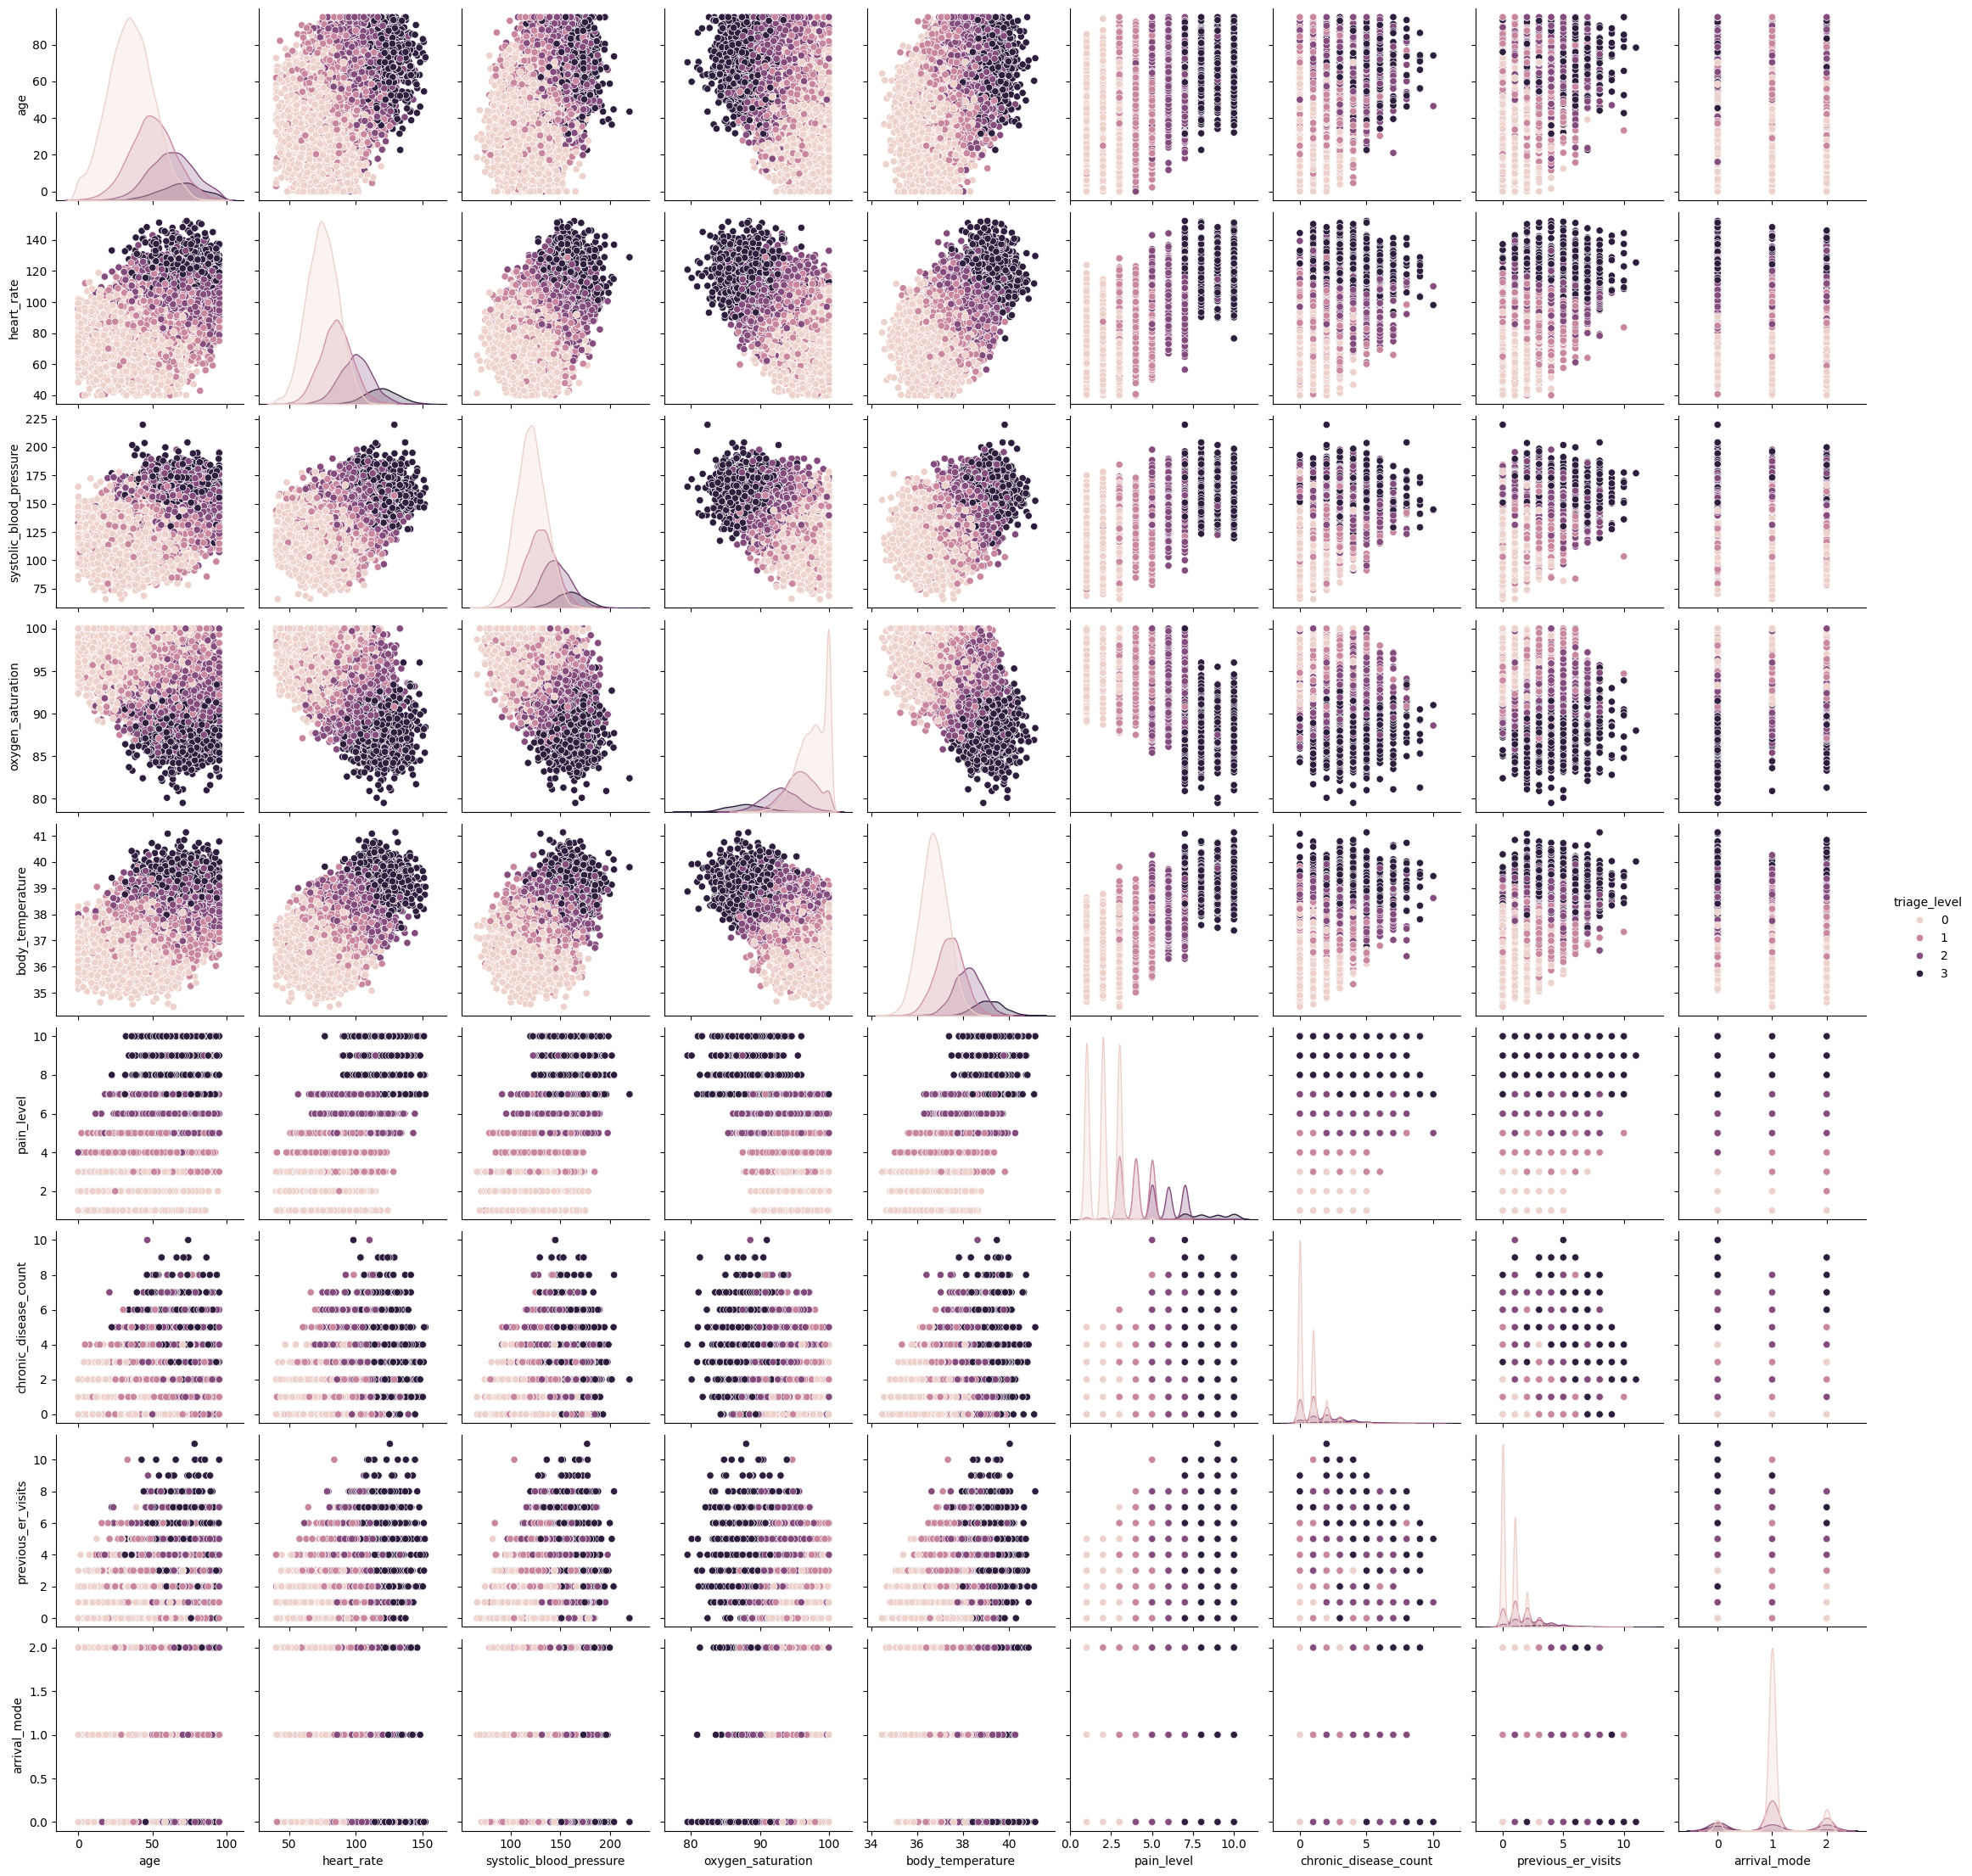

In [22]:
sns.pairplot(
    df,
    hue="triage_level"
)

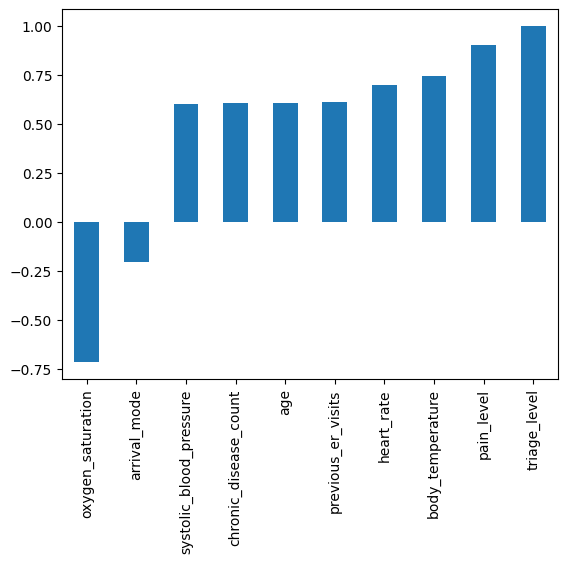

In [23]:
corr = df.corr()

corr["triage_level"].sort_values().plot(
    kind="bar"
)

plt.show()

In [24]:
x=df.drop("triage_level",axis=1)
y=df["triage_level"]

In [25]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(14400, 9)
(3600, 9)
(14400,)
(3600,)


In [26]:
scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

#logisticRegression

In [27]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=1000)
model.fit(x_train_scaled ,y_train)
prediction=model.predict(x_test_scaled)

In [28]:
print (prediction)

[1 0 0 ... 0 1 0]


In [29]:
#evaluation
from sklearn.metrics import accuracy_score
accuracy=accuracy_score(y_test,prediction)
print("accuracy:" ,accuracy)

accuracy: 0.9458333333333333


In [30]:
acc_log = accuracy

In [31]:
from sklearn.metrics import classification_report
print(classification_report(y_test,prediction))

              precision    recall  f1-score   support

           0       0.96      0.98      0.97      1985
           1       0.91      0.89      0.90       897
           2       0.93      0.92      0.93       540
           3       0.97      0.95      0.96       178

    accuracy                           0.95      3600
   macro avg       0.94      0.93      0.94      3600
weighted avg       0.95      0.95      0.95      3600



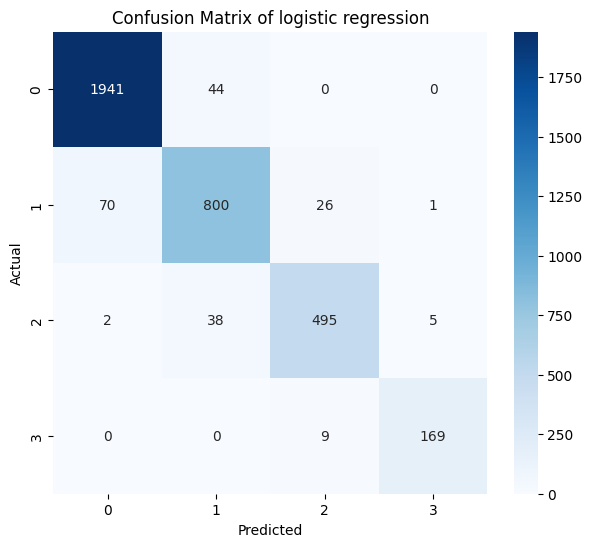

In [32]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, prediction)

plt.figure(figsize=(7,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix of logistic regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

#KNN MODELING

In [33]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(x_train_scaled, y_train)

prediction = knn.predict(x_test_scaled)

In [34]:
print(prediction)

[1 0 0 ... 0 1 0]


In [35]:
#evaluation
from sklearn.metrics import accuracy_score
accuracy=accuracy_score(y_test,prediction)
print("accuracy:" ,accuracy)

accuracy: 0.9211111111111111


In [36]:
acc_knn = accuracy

In [37]:
from sklearn.metrics import classification_report
print(classification_report(y_test,prediction))

              precision    recall  f1-score   support

           0       0.94      0.97      0.96      1985
           1       0.87      0.84      0.85       897
           2       0.91      0.87      0.89       540
           3       0.95      0.91      0.93       178

    accuracy                           0.92      3600
   macro avg       0.92      0.90      0.91      3600
weighted avg       0.92      0.92      0.92      3600



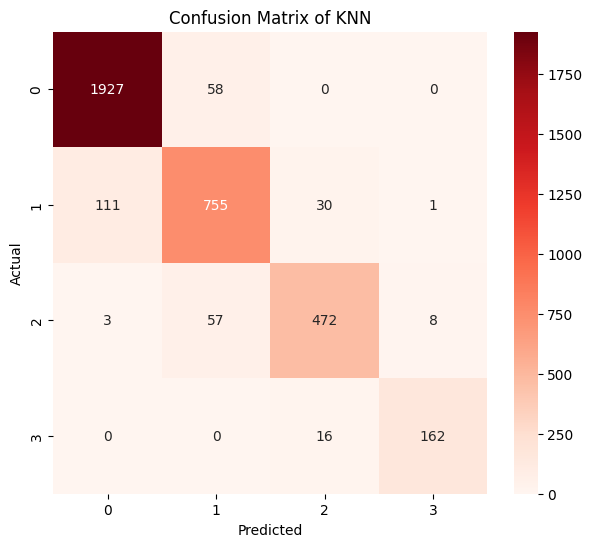

In [38]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, prediction)

plt.figure(figsize=(7,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Reds"
)

plt.title("Confusion Matrix of KNN")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

#decision tree

In [39]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42,max_depth=5)

dt.fit(x_train, y_train)

prediction = dt.predict(x_test)

print(prediction)

[0 0 0 ... 0 1 0]


In [40]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, prediction)

print("Accuracy:", accuracy)

Accuracy: 0.8955555555555555


In [41]:
acc_dt = accuracy

In [42]:

from sklearn.metrics import classification_report

print(classification_report(y_test, prediction))

              precision    recall  f1-score   support

           0       0.92      0.97      0.94      1985
           1       0.83      0.78      0.80       897
           2       0.88      0.83      0.85       540
           3       0.97      0.85      0.91       178

    accuracy                           0.90      3600
   macro avg       0.90      0.86      0.88      3600
weighted avg       0.89      0.90      0.89      3600



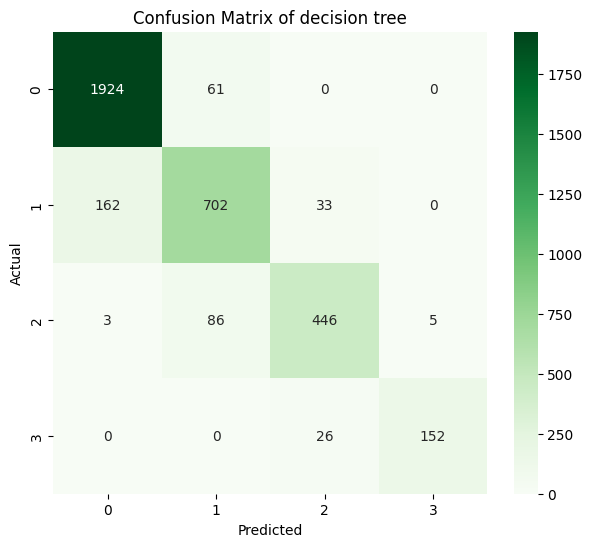

In [43]:
cm = confusion_matrix(y_test, prediction)

plt.figure(figsize=(7,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens"
)

plt.title("Confusion Matrix of decision tree")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

#random forest

In [44]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(x_train, y_train)

prediction = rf.predict(x_test)

print(prediction)

[1 0 0 ... 0 1 0]


In [45]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, prediction)

print("Accuracy:", accuracy)

Accuracy: 0.9416666666666667


In [46]:
acc_rf = accuracy

In [47]:
from sklearn.metrics import classification_report

print(classification_report(y_test, prediction))

              precision    recall  f1-score   support

           0       0.96      0.98      0.97      1985
           1       0.89      0.89      0.89       897
           2       0.93      0.90      0.91       540
           3       0.96      0.93      0.95       178

    accuracy                           0.94      3600
   macro avg       0.94      0.92      0.93      3600
weighted avg       0.94      0.94      0.94      3600



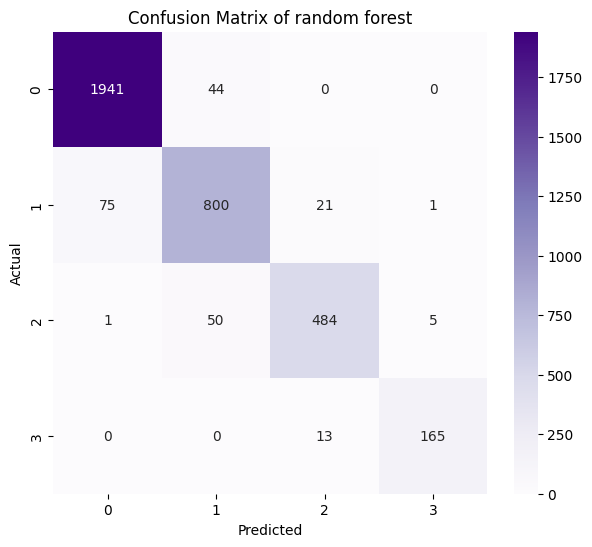

In [48]:
cm = confusion_matrix(y_test, prediction)

plt.figure(figsize=(7,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Purples"
)

plt.title("Confusion Matrix of random forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [49]:
importance = pd.Series(

    rf.feature_importances_,

    index=x.columns

)

importance = importance.sort_values(ascending=True)

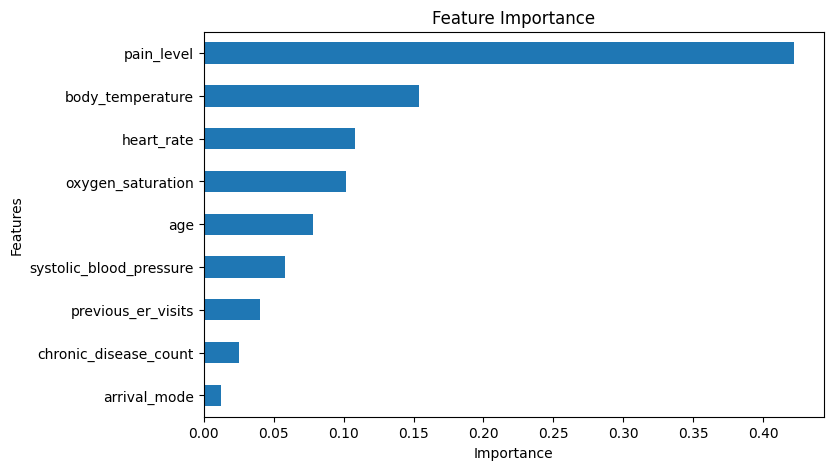

In [50]:
plt.figure(figsize=(8,5))

importance.plot(kind="barh")

plt.title("Feature Importance")

plt.xlabel("Importance")

plt.ylabel("Features")

plt.show()

In [51]:
results = pd.DataFrame({

    "Model":[
        "Logistic Regression",
        "KNN",
        "Decision Tree",
        "Random Forest"
    ],

    "Accuracy":[
        acc_log,
        acc_knn,
        acc_dt,
        acc_rf
    ]

})

print(results)


                 Model  Accuracy
0  Logistic Regression  0.945833
1                  KNN  0.921111
2        Decision Tree  0.895556
3        Random Forest  0.941667


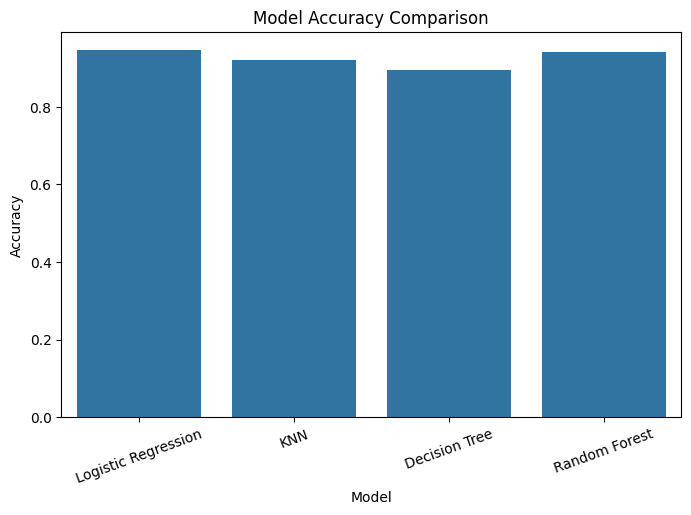

In [52]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=results,
    x="Model",
    y="Accuracy"
)

plt.xticks(rotation=20)

plt.title("Model Accuracy Comparison")

plt.show()

In [54]:
importance = pd.DataFrame(
    model.coef_,
    columns=df.drop("triage_level", axis=1).columns
)

importance.index = ["Class 0", "Class 1", "Class 2", "Class 3"]

print(importance)

              age  heart_rate  systolic_blood_pressure  oxygen_saturation  \
Class 0 -1.001649    -1.42921                -0.994218           1.384437   
Class 1 -0.232553    -0.57626                -0.416114           0.631721   
Class 2  0.460400     0.48239                 0.423118          -0.381843   
Class 3  0.773802     1.52308                 0.987214          -1.634315   

         body_temperature  pain_level  chronic_disease_count  \
Class 0         -1.788669   -6.312233              -0.819295   
Class 1         -0.651813   -1.615093              -0.108895   
Class 2          0.628072    2.578826               0.327113   
Class 3          1.812410    5.348500               0.601077   

         previous_er_visits  arrival_mode  
Class 0           -0.984618      0.104454  
Class 1           -0.040358      0.119030  
Class 2            0.336509     -0.015342  
Class 3            0.688467     -0.208142  


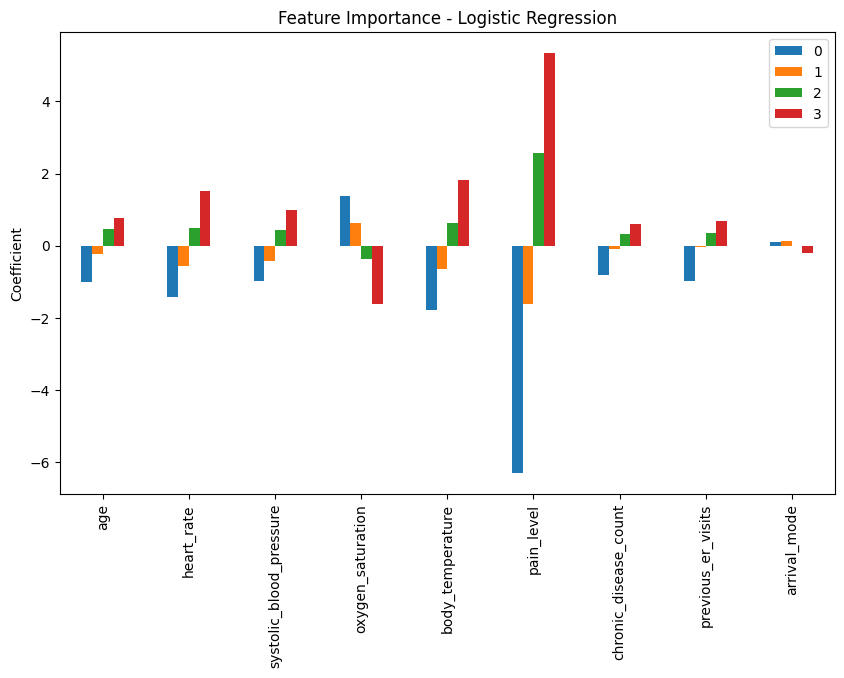

In [55]:
coef = pd.DataFrame(
    model.coef_,
    columns=x.columns,
    index=model.classes_
)

coef.T.plot(
    kind="bar",
    figsize=(10,6)
)

plt.title("Feature Importance - Logistic Regression")
plt.ylabel("Coefficient")
plt.show()

In [56]:
import joblib

joblib.dump(model, "Medical-Triage_model.pkl")


['Medical-Triage_model.pkl']

In [57]:
from google.colab import files

files.download("Medical-Triage_model.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [58]:
joblib.dump(scaler, "scaler.pkl")


['scaler.pkl']

In [59]:
files.download("scaler.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>